# Linear Regression with Scikit-Learn: Student Study Hours vs. Exam Scores
This notebook builds an end-to-end Simple Linear Regression model to predict student test scores based on study hours, following the workflow from the Stack Abuse Scikit-Learn guide:
1. **Exploratory Data Analysis (EDA)**
2. **Data Splitting & Preprocessing**
3. **Model Training (`LinearRegression`)**
4. **Model Evaluation ($MAE$, $MSE$, $RMSE$, $R^2$)**
5. **Prediction & Residual Visualizations**

In [2]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 1. Load the Dataset
We load the `student_scores.csv` dataset containing 25 records of study hours and exam percentages. A resilient fallback is included in case the remote URL is unreachable.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/AdiPersonalWorks/Random/master/student_scores%20-%20student_scores.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Dataset successfully fetched from remote repository.")
except Exception:
    csv_data = """Hours,Scores
2.5,21
5.1,47
3.2,27
8.5,75
3.5,30
1.5,20
9.2,88
5.5,60
8.3,81
2.7,25
7.7,85
5.9,62
4.5,41
3.3,42
1.1,17
8.9,95
2.5,30
1.9,24
6.1,67
7.4,69
2.7,30
4.8,54
3.8,35
6.9,76
7.8,86"""
    df = pd.read_csv(io.StringIO(csv_data))
    print("Remote fetch failed; loaded embedded dataset.")

df.head()

Dataset successfully fetched from remote repository.


,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


## 2. Exploratory Data Analysis (EDA)
Inspect dataset dimensions, summary statistics, Pearson correlation, and plot the bivariate relationship.

Dataset shape: (25, 2) (rows, columns)

Summary Statistics:


,Hours,Scores
count,25.000000,25.000000
mean,5.012000,51.480000
std,2.525094,25.286887
min,1.100000,17.000000
25%,2.700000,30.000000
50%,4.800000,47.000000
75%,7.400000,75.000000
max,9.200000,95.000000



Pearson correlation coefficient (r): 0.9762


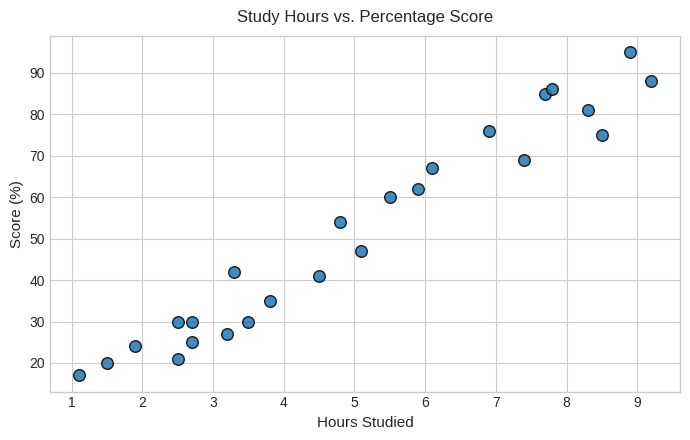

In [4]:
print(f"Dataset shape: {df.shape} (rows, columns)\n")
print("Summary Statistics:")
display(df.describe())

# Correlation check
corr_val = df['Hours'].corr(df['Scores'])
print(f"\nPearson correlation coefficient (r): {corr_val:.4f}")

# Scatter plot
plt.figure(figsize=(7, 4.5))
plt.scatter(df['Hours'], df['Scores'], color='#1f77b4', edgecolors='black', s=70, alpha=0.85)
plt.title("Study Hours vs. Percentage Score", fontsize=12, pad=10)
plt.xlabel("Hours Studied", fontsize=11)
plt.ylabel("Score (%)", fontsize=11)
plt.tight_layout()
plt.show()

## 3. Data Splitting & Feature Formatting
Scikit-Learn estimators require feature matrix `X` to be a 2D array of shape `(n_samples, n_features)`. We split the data into **80% training** and **20% testing** using `random_state=42`.

In [6]:
# Feature matrix (2D) and target vector (1D)
X = df[['Hours']].values
y = df['Scores'].values

SEED = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape : {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape : {y_test.shape}")

X_train shape: (20, 1)
X_test shape : (5, 1)
y_train shape: (20,)
y_test shape : (5,)


## 4. Train the Linear Regression Model
Fit the ordinary least squares linear regression model:
$$y = m \cdot x + b$$
where $m$ is the slope (`coef_`) and $b$ is the intercept (`intercept_`).

In [7]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)

m = regressor.coef_[0]
b = regressor.intercept_

print(f"Slope (m / coef_)    : {m:.4f}")
print(f"Intercept (b)        : {b:.4f}")
print(f"Learned Equation     : Score = ({m:.4f} * Hours) + {b:.4f}")

Slope (m / coef_)    : 9.6821
Intercept (b)        : 2.8269
Learned Equation     : Score = (9.6821 * Hours) + 2.8269


## 5. Model Evaluation & Visualization
Generate predictions on the unseen test set, inspect residuals, and compute regression performance metrics:
* **MAE** (Mean Absolute Error)
* **MSE** (Mean Squared Error)
* **RMSE** (Root Mean Squared Error)
* **$R^2$** (Coefficient of Determination)

,Hours,Actual Score,Predicted Score,Residual (Error)
0,8.3,81,83.19,-2.19
1,2.5,30,27.03,2.97
2,2.5,21,27.03,-6.03
3,6.9,76,69.63,6.37
4,5.9,62,59.95,2.05



Model Metrics:
MAE  : 3.9208
MSE  : 18.9432
RMSE : 4.3524
R²   : 0.9678


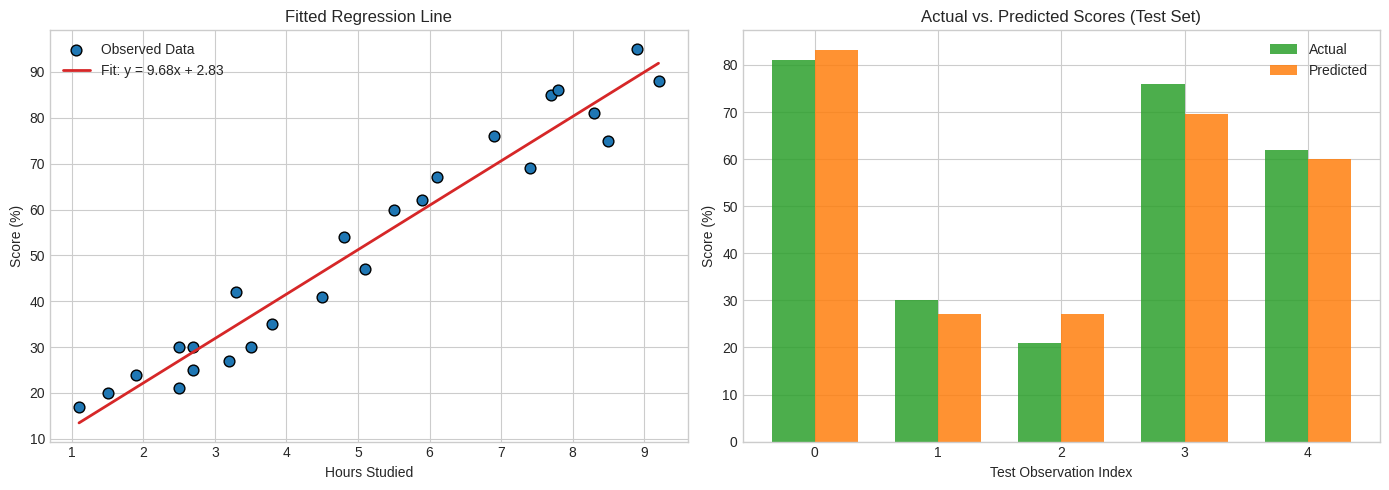

In [8]:
y_pred = regressor.predict(X_test)

# Prediction comparison table
results_df = pd.DataFrame({
    'Hours': X_test.flatten(),
    'Actual Score': y_test,
    'Predicted Score': np.round(y_pred, 2),
    'Residual (Error)': np.round(y_test - y_pred, 2)
})
display(results_df)

# Metrics calculation
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = metrics.r2_score(y_test, y_pred)

print("\nModel Metrics:")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

# Visualizations: Regression line + Test set comparisons
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Regression fit line over all data
axes[0].scatter(X, y, color='#1f77b4', edgecolors='black', label='Observed Data', s=60)
x_span = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
axes[0].plot(x_span, regressor.predict(x_span), color='#d62728', linewidth=2, label=f'Fit: y = {m:.2f}x + {b:.2f}')
axes[0].set_title("Fitted Regression Line", fontsize=12)
axes[0].set_xlabel("Hours Studied")
axes[0].set_ylabel("Score (%)")
axes[0].legend()

# 2. Actual vs. Predicted bar chart (Test set)
bar_width = 0.35
indices = np.arange(len(y_test))
axes[1].bar(indices - bar_width/2, y_test, bar_width, label='Actual', color='#2ca02c', alpha=0.85)
axes[1].bar(indices + bar_width/2, y_pred, bar_width, label='Predicted', color='#ff7f0e', alpha=0.85)
axes[1].set_title("Actual vs. Predicted Scores (Test Set)", fontsize=12)
axes[1].set_xlabel("Test Observation Index")
axes[1].set_ylabel("Score (%)")
axes[1].set_xticks(indices)
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Single-Sample Inference
Pass any hypothetical study hours value to estimate the predicted final exam score.

In [9]:
hours_input = 9.25
prediction = regressor.predict([[hours_input]])[0]

print(f"Hours Studied   : {hours_input}")
print(f"Predicted Score : {prediction:.2f}%")

Hours Studied   : 9.25
Predicted Score : 92.39%
